# Practical No-04: Image Generation using Deep Convolutional GAN (DCGAN)

**Student:** Yadnesh Tayade  
**PRN:** 202401110057

**Dataset:** Oxford Flowers 102 – flower photographs across 102 categories

**Aim:** Implement and train a DCGAN, generate synthetic flower images, and evaluate it by analysing the Generator / Discriminator loss curves and the quality of generated images.

## Objectives
1. Load and preprocess a standard image dataset.
2. Implement the DCGAN Generator and Discriminator with convolutional layers.
3. Configure adversarial training using binary cross-entropy and Adam optimizers.
4. Generate new samples and inspect training loss, diversity, and possible mode collapse.
5. Save the trained weights

## 1. Setup and Imports
Run on a GPU runtime

In [3]:
!pip install importlib_resources
import os, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow_datasets as tfds

print('TensorFlow:', tf.__version__)
print('GPU available:', tf.config.list_physical_devices('GPU'))

# reproducibility
np.random.seed(42)
tf.random.set_seed(42)

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load the Oxford Flowers 102 Dataset
We load the training and validation splits, centre-crop each image to a square, resize it to **64×64**, and scale pixels from `[0, 255]` to `[-1, 1]` to match the generator's `tanh` output.

If TensorFlow Datasets is not installed in Colab, run `!pip -q install tensorflow-datasets` in a separate cell first.

In [4]:
IMG_SIZE = 64

(ds_train, ds_info) = tfds.load(
    'oxford_flowers102',
    split='train+validation',
    as_supervised=True,
    with_info=True,
    shuffle_files=True
)

print('Dataset:', ds_info.name)
print('Training + validation images:', ds_info.splits['train'].num_examples + ds_info.splits['validation'].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

...

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_flowers102/incomplete.I7LC0F_2.1.1/oxford_flowers102-test.tfrecord-…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_flowers102/incomplete.I7LC0F_2.1.1/oxford_flowers102-validation.tfr…

Dataset oxford_flowers102 downloaded and prepared to /root/tensorflow_datasets/oxford_flowers102/2.1.1. Subsequent calls will reuse this data.
Dataset: oxford_flowers102
Training + validation images: 2040


In [5]:
def load_real_samples(ds, size=IMG_SIZE, limit=2000):
    X = []
    for image, label in tfds.as_numpy(ds.take(limit)):
        img = Image.fromarray(image).convert('RGB')
        w, h = img.size
        s = min(w, h)
        left, top = (w - s) // 2, (h - s) // 2
        img = img.crop((left, top, left + s, top + s)).resize((size, size), Image.Resampling.LANCZOS)
        X.append(np.asarray(img, dtype='float32'))
    X = np.asarray(X, dtype='float32')
    X = (X - 127.5) / 127.5
    return X

dataset = load_real_samples(ds_train)
print('Dataset shape:', dataset.shape, '| min/max:', dataset.min(), dataset.max())

Dataset shape: (2000, 64, 64, 3) | min/max: -1.0 1.0


A look at some real training images:

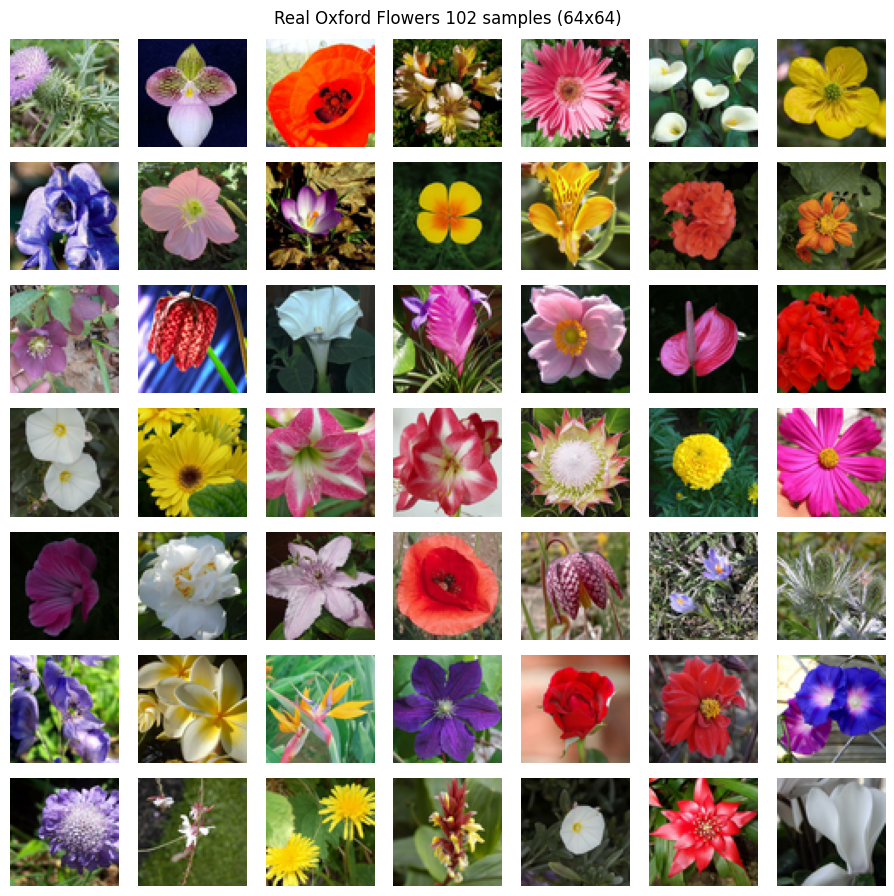

In [6]:
def plot_grid(images, n=7, title=None, save=None):
    images = (images + 1) / 2.0                         # [-1,1] -> [0,1]
    plt.figure(figsize=(n * 1.3, n * 1.3))
    for i in range(n * n):
        plt.subplot(n, n, 1 + i)
        plt.axis('off')
        plt.imshow(np.clip(images[i], 0, 1))
    if title: plt.suptitle(title)
    plt.tight_layout()
    if save: plt.savefig(save, dpi=120)
    plt.show()

idx = np.random.choice(len(dataset), 49, replace=False)
plot_grid(dataset[idx], title='Real Oxford Flowers 102 samples (64x64)')

## 3. Define the Discriminator
The discriminator is a CNN binary classifier (real = 1, fake = 0). It uses **strided convolutions** instead of pooling to downsample (64→32→16→8→4), **LeakyReLU(0.2)** activations, dropout, and a sigmoid output. Optimiser: Adam (lr = 0.0002, β₁ = 0.5).

In [7]:
def define_discriminator(in_shape=(IMG_SIZE, IMG_SIZE, 3)):
    model = keras.Sequential(name='discriminator')
    model.add(layers.Input(shape=in_shape))
    # 64x64 -> 32x32
    model.add(layers.Conv2D(64, (4, 4), strides=(2, 2), padding='same'))
    model.add(layers.LeakyReLU(0.2))
    # 32x32 -> 16x16
    model.add(layers.Conv2D(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(layers.LeakyReLU(0.2))
    # 16x16 -> 8x8
    model.add(layers.Conv2D(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(layers.LeakyReLU(0.2))
    # 8x8 -> 4x4
    model.add(layers.Conv2D(256, (4, 4), strides=(2, 2), padding='same'))
    model.add(layers.LeakyReLU(0.2))
    # classifier
    model.add(layers.Flatten())
    model.add(layers.Dropout(0.4))
    model.add(layers.Dense(1, activation='sigmoid'))
    return model

d_model = define_discriminator()
d_model.summary()

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 925,249 (3.53 MB)

 Trainable params: 925,249 (3.53 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Define the Generator
The generator maps a **100-dimensional latent vector** (Gaussian noise) to a 64×64×3 image. Batch normalisation supports training, and the output uses **tanh** so pixels lie in `[-1, 1]`, matching the real data scaling.

In [8]:
LATENT_DIM = 100

def define_generator(latent_dim=LATENT_DIM):
    model = keras.Sequential(name='generator')
    model.add(layers.Input(shape=(latent_dim,)))
    # foundation for 4x4 image
    model.add(layers.Dense(256 * 4 * 4))
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Reshape((4, 4, 256)))
    # 4 -> 8
    model.add(layers.Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    # 8 -> 16
    model.add(layers.Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    # 16 -> 32
    model.add(layers.Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    # 32 -> 64
    model.add(layers.Conv2DTranspose(64, (4, 4), strides=(2, 2), padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    # output layer
    model.add(layers.Conv2D(3, (3, 3), activation='tanh', padding='same'))
    return model

g_model = define_generator()
g_model.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 4096)           │       413,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       524,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 128)    │       262,272 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 128)    │       262,272 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 64, 64, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 3)      │         1,731 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,597,315 (6.09 MB)

 Trainable params: 1,596,419 (6.09 MB)

 Non-trainable params: 896 (3.50 KB)

Before training, the generator produces only random noise – this is the baseline we will compare against:

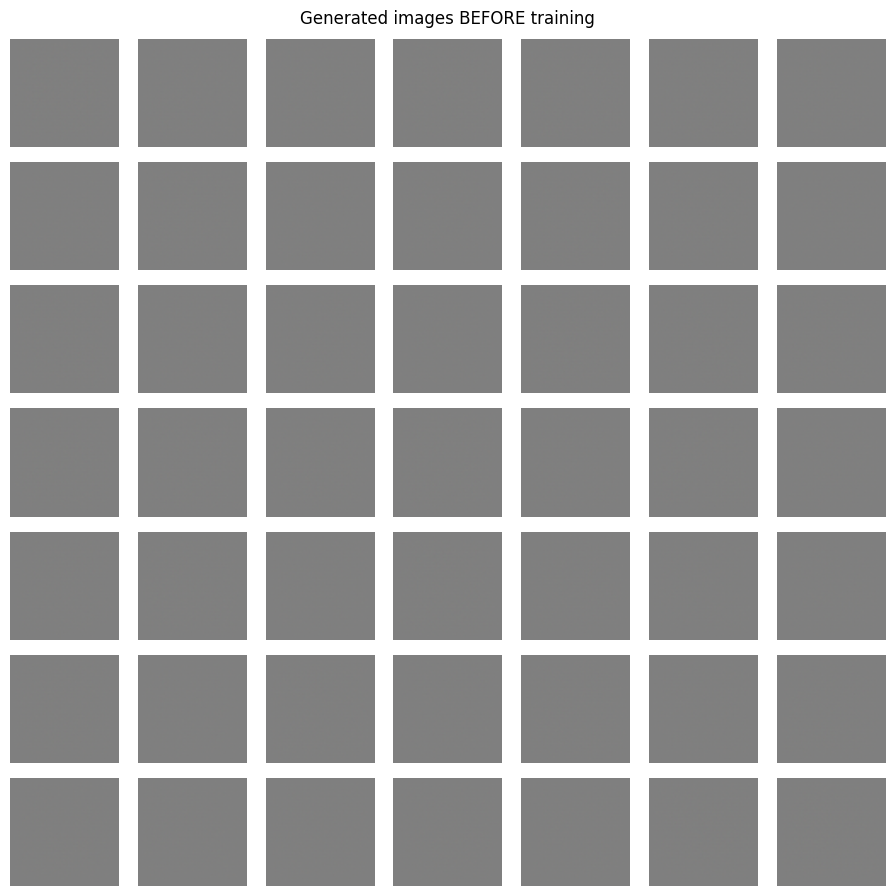

In [9]:
def generate_latent_points(latent_dim, n_samples):
    return np.random.randn(n_samples, latent_dim).astype('float32')

noise_imgs = g_model.predict(generate_latent_points(LATENT_DIM, 49), verbose=0)
plot_grid(noise_imgs, title='Generated images BEFORE training')

## 5. Adversarial Training Setup
Training alternates between two steps for every batch:

1. **Discriminator step** – train on real images (label 1) and generated images (label 0). One-sided label smoothing uses real label = 0.9.
2. **Generator step** – train the generator so generated images are classified as real.

The training uses `tf.GradientTape` to update each network separately. Random horizontal and vertical flips are applied to real images as data augmentation.

In [10]:
BATCH_SIZE = 64          # 32 real + 32 fake for the discriminator
HALF_BATCH = BATCH_SIZE // 2
EPOCHS     = 5           # short run for the submission deadline
LR, BETA1  = 0.0002, 0.5

bce   = keras.losses.BinaryCrossentropy()
d_opt = keras.optimizers.Adam(LR, beta_1=BETA1)
g_opt = keras.optimizers.Adam(LR, beta_1=BETA1)

def generate_real_samples(dataset, n_samples):
    ix = np.random.randint(0, dataset.shape[0], n_samples)
    X = dataset[ix].copy()
    flip_h = np.random.rand(n_samples) < 0.5            # augmentation
    flip_v = np.random.rand(n_samples) < 0.5
    X[flip_h] = X[flip_h][:, :, ::-1, :]
    X[flip_v] = X[flip_v][:, ::-1, :, :]
    y = np.ones((n_samples, 1), dtype='float32') * 0.9  # one-sided label smoothing
    return X, y

def generate_fake_samples(g_model, latent_dim, n_samples):
    x_input = generate_latent_points(latent_dim, n_samples)
    X = g_model.predict(x_input, verbose=0)
    y = np.zeros((n_samples, 1), dtype='float32')
    return X, y

@tf.function
def train_d_step(real_x, real_y, fake_x, fake_y):
    with tf.GradientTape() as tape:
        p_real = d_model(real_x, training=True)
        p_fake = d_model(fake_x, training=True)
        d_loss_real = bce(real_y, p_real)
        d_loss_fake = bce(fake_y, p_fake)
        d_loss = 0.5 * (d_loss_real + d_loss_fake)
    grads = tape.gradient(d_loss, d_model.trainable_variables)
    d_opt.apply_gradients(zip(grads, d_model.trainable_variables))
    acc_real = tf.reduce_mean(tf.cast(p_real > 0.5, tf.float32))
    acc_fake = tf.reduce_mean(tf.cast(p_fake < 0.5, tf.float32))
    return d_loss, acc_real, acc_fake

@tf.function
def train_g_step(z):
    with tf.GradientTape() as tape:
        fake = g_model(z, training=True)
        pred = d_model(fake, training=False)            # discriminator frozen here
        g_loss = bce(tf.ones_like(pred), pred)          # inverted labels: fake -> "real"
    grads = tape.gradient(g_loss, g_model.trainable_variables)   # only generator weights
    g_opt.apply_gradients(zip(grads, g_model.trainable_variables))
    return g_loss

## 6. Train the DCGAN
Per-epoch averages of the generator loss, discriminator loss and discriminator accuracy (on real / fake) are stored in `history` so they can be plotted afterwards. A grid of generated images is shown/saved every 10 epochs so we can watch quality improve, and the generator is checkpointed.

Epoch   1/5 | D loss 0.306 | G loss 4.133 | D acc real 99% fake 91% | 19s


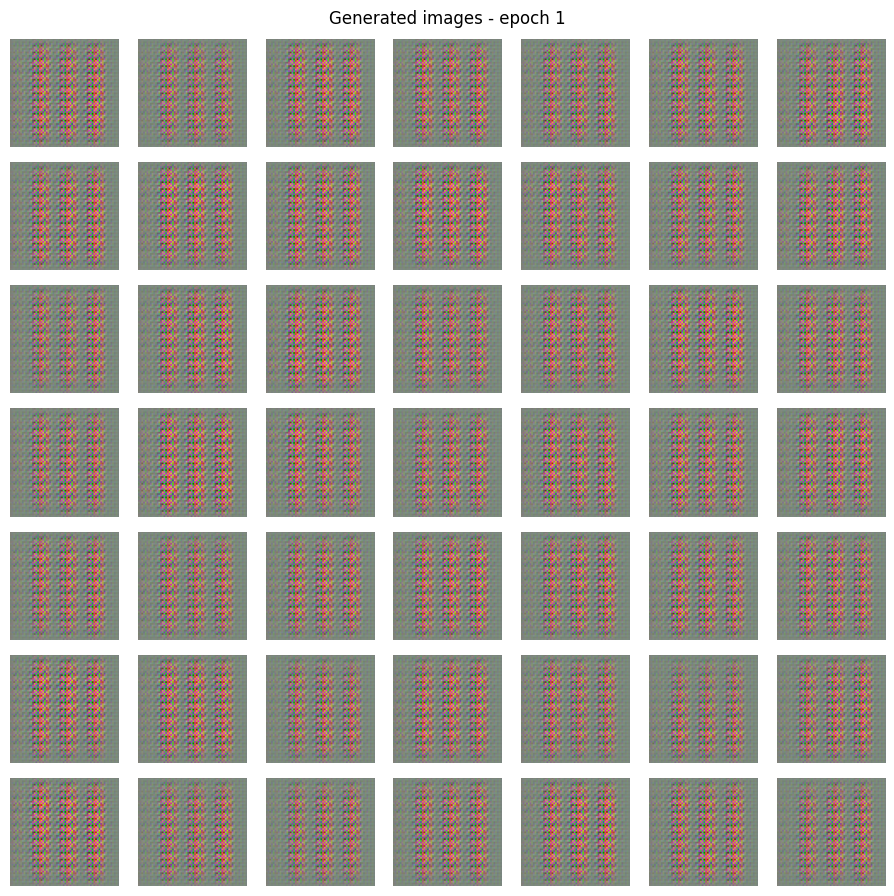

Epoch   2/5 | D loss 0.169 | G loss 0.151 | D acc real 100% fake 100% | 31s
Epoch   3/5 | D loss 0.189 | G loss 2.468 | D acc real 99% fake 98% | 41s
Epoch   4/5 | D loss 0.244 | G loss 2.802 | D acc real 98% fake 99% | 50s
Epoch   5/5 | D loss 0.271 | G loss 2.671 | D acc real 94% fake 97% | 60s


In [11]:
os.makedirs('outputs', exist_ok=True)
FIXED_NOISE = generate_latent_points(LATENT_DIM, 49)    # same noise every time -> comparable progress
history = {'d_loss': [], 'g_loss': [], 'acc_real': [], 'acc_fake': []}

def summarize_performance(epoch, g_model):
    imgs = g_model.predict(FIXED_NOISE, verbose=0)
    plot_grid(imgs, title=f'Generated images - epoch {epoch+1}',
              save=f'outputs/generated_e{epoch+1:03d}.png')
    g_model.save(f'outputs/generator_e{epoch+1:03d}.keras')

def train(g_model, d_model, dataset, latent_dim, n_epochs=EPOCHS, n_batch=BATCH_SIZE):
    bat_per_epo = dataset.shape[0] // HALF_BATCH
    start = time.time()
    for i in range(n_epochs):
        dl, gl, ar, af = [], [], [], []
        for j in range(bat_per_epo):
            X_real, y_real = generate_real_samples(dataset, HALF_BATCH)
            X_fake, y_fake = generate_fake_samples(g_model, latent_dim, HALF_BATCH)
            d_loss, a_r, a_f = train_d_step(X_real, y_real, X_fake, y_fake)
            g_loss = train_g_step(generate_latent_points(latent_dim, n_batch))
            dl.append(float(d_loss)); gl.append(float(g_loss))
            ar.append(float(a_r));    af.append(float(a_f))
        history['d_loss'].append(np.mean(dl));  history['g_loss'].append(np.mean(gl))
        history['acc_real'].append(np.mean(ar)); history['acc_fake'].append(np.mean(af))
        print(f'Epoch {i+1:3d}/{n_epochs} | D loss {history["d_loss"][-1]:.3f} | '
              f'G loss {history["g_loss"][-1]:.3f} | D acc real {history["acc_real"][-1]*100:.0f}% '
              f'fake {history["acc_fake"][-1]*100:.0f}% | {time.time()-start:.0f}s')
        if (i + 1) % 10 == 0 or i == 0:
            summarize_performance(i, g_model)

train(g_model, d_model, dataset, LATENT_DIM)
g_model.save('outputs/generator_final.keras')
d_model.save('outputs/discriminator_final.keras')

## 7. Evaluation

### 7.1 Generator and Discriminator Loss Curves
How to read them:
* GAN losses compete and do not need to decrease smoothly.
* A discriminator loss near 0.69 can indicate it is having difficulty distinguishing real from fake.
* If the discriminator dominates, generator loss may rise and image quality may remain poor. Check both curves and generated samples.

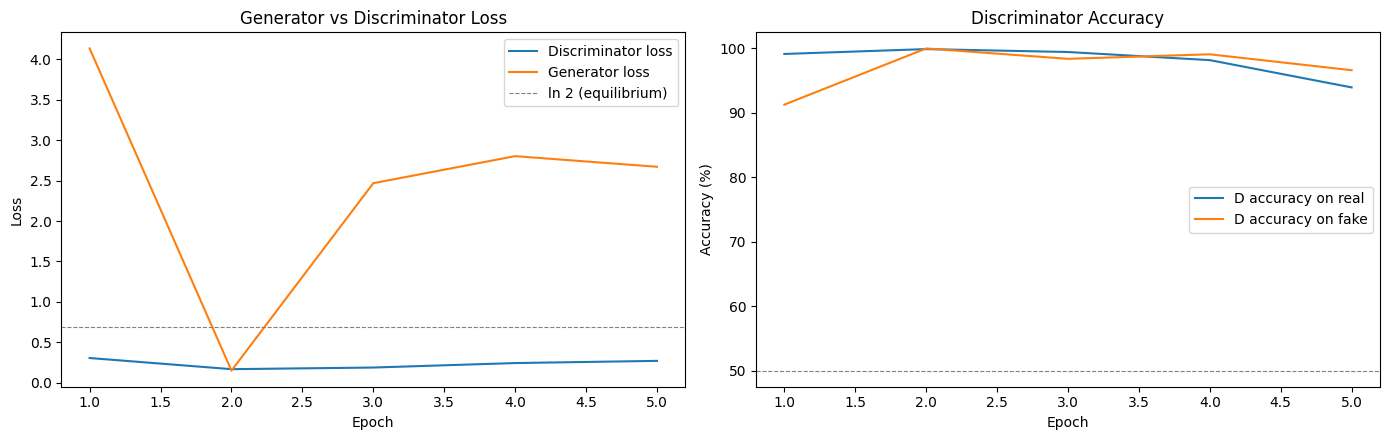

In [12]:
epochs_range = np.arange(1, len(history['d_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

ax[0].plot(epochs_range, history['d_loss'], label='Discriminator loss')
ax[0].plot(epochs_range, history['g_loss'], label='Generator loss')
ax[0].axhline(np.log(2), color='gray', ls='--', lw=0.8, label='ln 2 (equilibrium)')
ax[0].set_title('Generator vs Discriminator Loss'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss'); ax[0].legend()

ax[1].plot(epochs_range, np.array(history['acc_real']) * 100, label='D accuracy on real')
ax[1].plot(epochs_range, np.array(history['acc_fake']) * 100, label='D accuracy on fake')
ax[1].axhline(50, color='gray', ls='--', lw=0.8)
ax[1].set_title('Discriminator Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy (%)'); ax[1].legend()

plt.tight_layout(); plt.savefig('outputs/loss_curves.png', dpi=130); plt.show()

### 7.2 Generate Synthetic Images with the Trained Generator

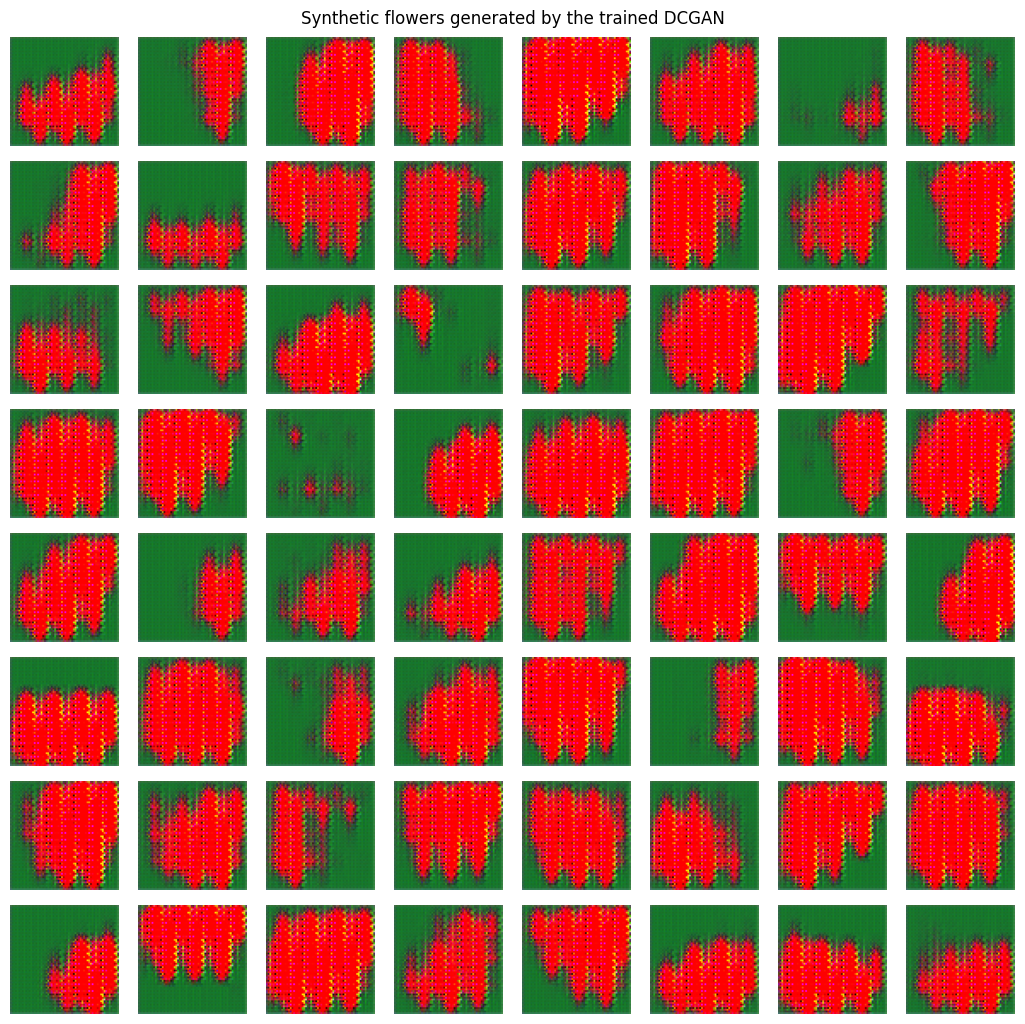

In [13]:
n = 8
z = generate_latent_points(LATENT_DIM, n * n)
fake_imgs = g_model.predict(z, verbose=0)
plot_grid(fake_imgs, n=n, title='Synthetic flowers generated by the trained DCGAN',
          save='outputs/final_generated.png')

### 7.3 Real vs Generated Images (side by side)

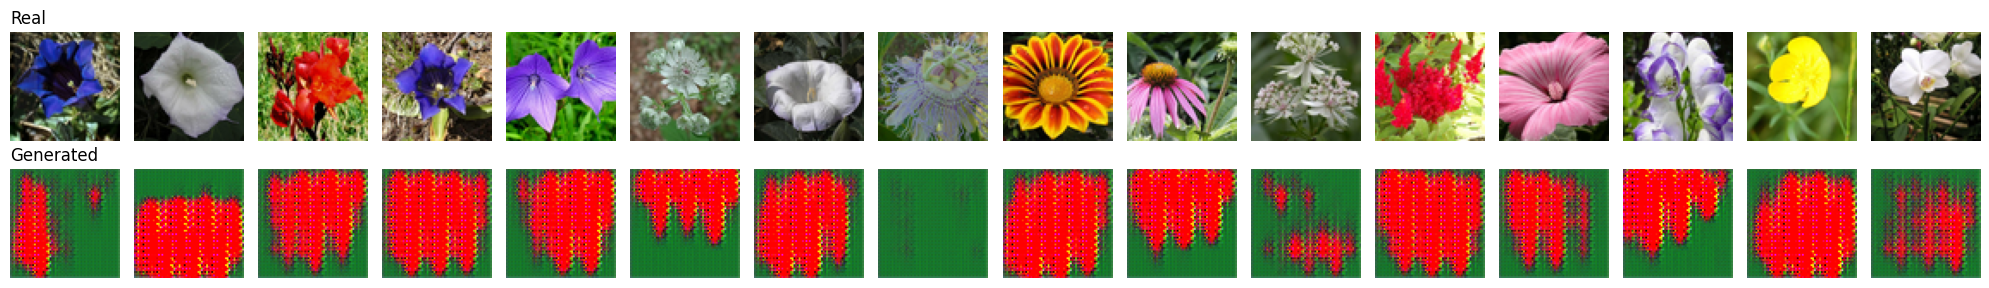

In [14]:
real_show = dataset[np.random.choice(len(dataset), 16, replace=False)]
fake_show = g_model.predict(generate_latent_points(LATENT_DIM, 16), verbose=0)
fig, ax = plt.subplots(2, 16, figsize=(20, 3))
for i in range(16):
    ax[0, i].imshow((real_show[i] + 1) / 2); ax[0, i].axis('off')
    ax[1, i].imshow(np.clip((fake_show[i] + 1) / 2, 0, 1)); ax[1, i].axis('off')
ax[0, 0].set_title('Real', loc='left'); ax[1, 0].set_title('Generated', loc='left')
plt.tight_layout(); plt.savefig('outputs/real_vs_fake.png', dpi=130); plt.show()

### 7.4 Latent-Space Interpolation
Smoothly moving between two latent vectors creates a sequence of generated images, allowing visual inspection of changes in the generator's output.

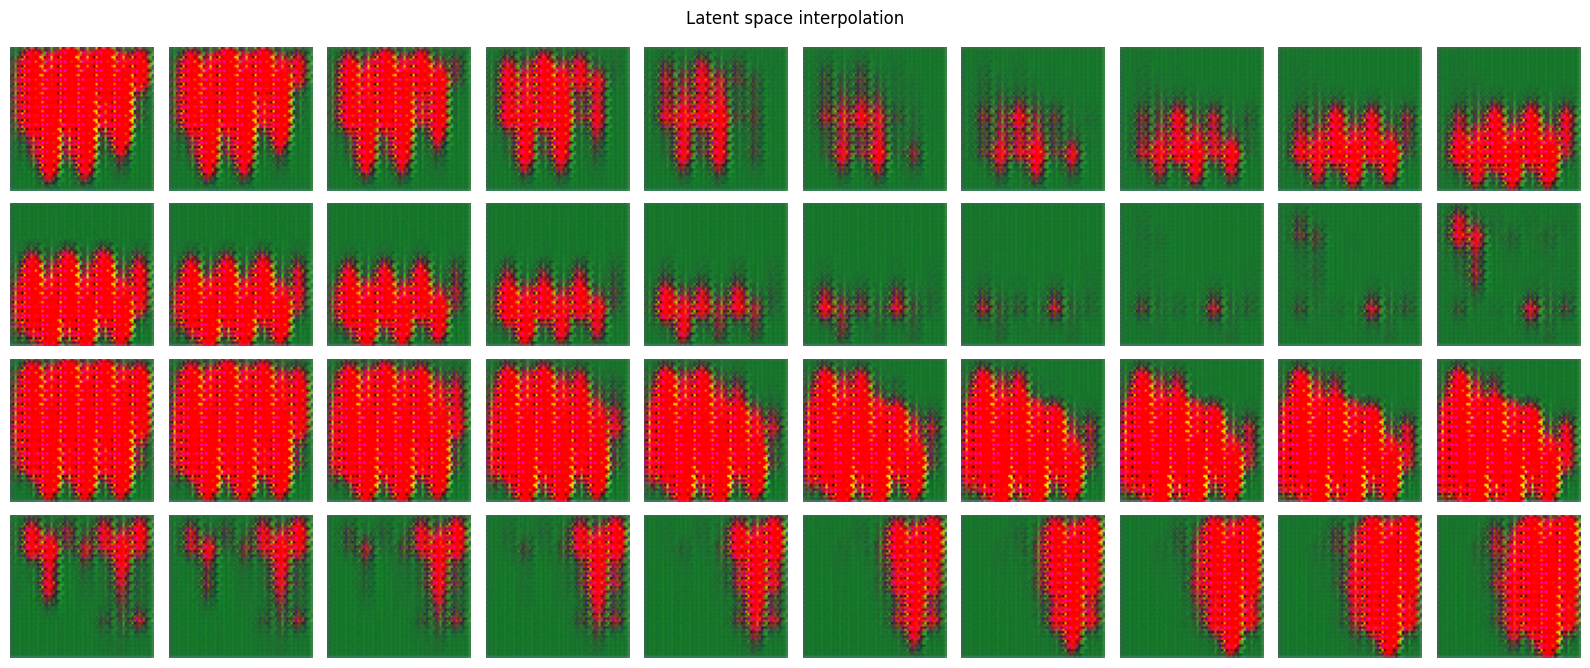

In [15]:
def interpolate(z1, z2, steps=10):
    ratios = np.linspace(0, 1, steps)
    return np.array([(1 - r) * z1 + r * z2 for r in ratios])

rows = 4
fig, ax = plt.subplots(rows, 10, figsize=(16, rows * 1.7))
for r in range(rows):
    zs = interpolate(np.random.randn(LATENT_DIM), np.random.randn(LATENT_DIM))
    imgs = (g_model.predict(zs.astype('float32'), verbose=0) + 1) / 2
    for c in range(10):
        ax[r, c].imshow(np.clip(imgs[c], 0, 1)); ax[r, c].axis('off')
plt.suptitle('Latent space interpolation'); plt.tight_layout(); plt.show()

### 7.5 Quantitative Metric – Fréchet Inception Distance (FID)
FID compares feature statistics of real and generated images using a pretrained InceptionV3 network. **Lower is better.** This cell may take extra time to download pretrained weights and calculate the metric; if time is short, skip it and report the loss curves and visual evaluation.

In [16]:
from scipy import linalg

def calculate_fid(real, fake, batch=100):
    inc = keras.applications.InceptionV3(include_top=False, pooling='avg',
                                         input_shape=(299, 299, 3))
    def feats(x):
        x = (x + 1) / 2 * 255.0
        out = []
        for i in range(0, len(x), batch):
            b = tf.image.resize(x[i:i + batch], (299, 299)).numpy()
            b = keras.applications.inception_v3.preprocess_input(b)
            out.append(inc.predict(b, verbose=0))
        return np.concatenate(out)
    f1, f2 = feats(real), feats(fake)
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean = linalg.sqrtm(s1.dot(s2))
    if np.iscomplexobj(covmean): covmean = covmean.real
    return float(np.sum((mu1 - mu2) ** 2) + np.trace(s1 + s2 - 2.0 * covmean))

try:
    N = 1000
    real_s = dataset[np.random.choice(len(dataset), N, replace=False)]
    fake_s = g_model.predict(generate_latent_points(LATENT_DIM, N), verbose=0)
    noise_s = np.random.uniform(-1, 1, real_s.shape).astype('float32')
    print('FID (trained generator vs real): %.2f' % calculate_fid(real_s, fake_s))
    print('FID (random noise vs real)     : %.2f  <- baseline' % calculate_fid(real_s, noise_s))
except Exception as e:
    print('FID skipped:', e)

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
FID (trained generator vs real): 407.07
FID (random noise vs real)     : 387.59  <- baseline


## 8. Results and Discussion

After running the notebook, write observations based on your actual outputs.

- Preprocessing: The Oxford Flowers 102 dataset was used for training. Images were resized to 64×64 pixels and normalized to the range [−1,1] to match the Generator's tanh output activation.

- Architecture: The Generator transforms random latent vectors into synthetic flower images, while the Discriminator learns to distinguish real flower images from generated ones.

- Training: The Generator and Discriminator were trained alternately using separate optimizers. Their losses were monitored to observe the learning process and the competition between the two networks.

**Loss curves**
* Describe how Generator and Discriminator losses change during the run. GAN losses do not necessarily decrease monotonically.
* Discuss whether either network appears to dominate, using the loss and accuracy curves.

**Image quality**
* Compare the real flower images with the generated samples.
* Note visible colour variation, flower-like structures, blur, repeated patterns, or lack of diversity.
* Do not claim realistic results unless the generated images support that conclusion.

**Limitations / improvements**
* Five epochs is a short training run, so outputs may be blurry or noisy.
* Improvements include longer training, more data, tuning learning rates, and evaluating FID after training.


In [19]:
import os
import time
import numpy as np

# Create output directory
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Display project results
print("=" * 50)
print("       DCGAN PROJECT - FINAL RESULTS")
print("=" * 50)

print("DATASET USED: Oxford Flowers 102")
print("Images available:", len(dataset))
print("Image tensor shape:", tuple(dataset.shape[1:]))
print("Epochs completed:", len(history['d_loss']))

print(f"Final Discriminator loss: {history['d_loss'][-1]:.4f}")
print(f"Final Generator loss:     {history['g_loss'][-1]:.4f}")

print(
    f"Final Discriminator accuracy on real images: "
    f"{history['acc_real'][-1] * 100:.1f}%"
)

print(
    f"Final Discriminator accuracy on generated images: "
    f"{history['acc_fake'][-1] * 100:.1f}%"
)

# Display training time if it was recorded
if 'training_seconds' in globals():
    print(f"Training time: {training_seconds:.1f} seconds")
else:
    print("Training time: Not recorded")

# Generate sample images
final_images = g_model.predict(
    generate_latent_points(LATENT_DIM, 16),
    verbose=0
)

print("Generated batch shape:", tuple(final_images.shape))

# Save trained models
g_model.save(os.path.join(OUTPUT_DIR, "dcgan_flowers_generator.keras"))
d_model.save(os.path.join(OUTPUT_DIR, "dcgan_flowers_discriminator.keras"))

print("Generator saved successfully.")
print("Discriminator saved successfully.")
print("Output directory:", OUTPUT_DIR)


       DCGAN PROJECT - FINAL RESULTS
DATASET USED: Oxford Flowers 102
Images available: 2000
Image tensor shape: (64, 64, 3)
Epochs completed: 5
Final Discriminator loss: 0.2712
Final Generator loss:     2.6707
Final Discriminator accuracy on real images: 94.0%
Final Discriminator accuracy on generated images: 96.6%
Training time: Not recorded
Generated batch shape: (16, 64, 64, 3)
Generator saved successfully.
Discriminator saved successfully.
Output directory: outputs


## 9. Conclusion
A DCGAN was trained on Oxford Flowers 102. The Generator and Discriminator loss curves and generated image grid were used to evaluate training behaviour and synthetic image quality.